# **Multiclass**

## **Training**
The below command was used to train the MORAL multiclass model on the credit multiclass dataset, were we splitted 'education level' into three categories to make a categorical sensitive attribute

In [1]:
# ! python main.py --fair_model moral-mc --model gae --dataset credit_multiclass_2 --device cuda:0 --epochs 500
# ! python main.py --fair_model moral-mc --model gae --dataset credit_multiclass_3 --device cuda:0 --epochs 500
# ! python main.py --fair_model moral-mc --model gae --dataset credit_multiclass_4 --device cuda:0 --epochs 500
# ! python main.py --fair_model moral-mc --model gae --dataset credit_multiclass_5 --device cuda:0 --epochs 500
# ! python main.py --fair_model moral-mc --model gae --dataset credit_multiclass_6 --device cuda:0 --epochs 500
# ! python main.py --fair_model moral-mc --model gae --dataset credit_multiclass_7 --device cuda:0 --epochs 500
# ! python main.py --fair_model moral-mc --model gae --dataset credit_multiclass_8 --device cuda:0 --epochs 500
# ! python main.py --fair_model moral-mc --model gae --dataset credit_multiclass_9 --device cuda:0 --epochs 500
# ! python main.py --fair_model moral-mc --model gae --dataset credit_multiclass_10 --device cuda:0 --epochs 500

## **Results**

In [ ]:
from helpers.metrics import get_results, print_results
from helpers.plots import plot_two_metrics
from helpers.plots import plot_one_metric

In [3]:
datasets_results= [
    "credit_multiclass_2",
    "credit_multiclass_3", 
    "credit_multiclass_4",
    "credit_multiclass_5",
    "credit_multiclass_6",
    "credit_multiclass_7",
    "credit_multiclass_8",
    "credit_multiclass_9",
    "credit_multiclass_10"
]
split_path = "../data/splits"
output_folder = "../data/output"
csv_out = f"{output_folder}/MORAL_edge_distributions.csv"
k = 1000

results = get_results(
    datasets=datasets_results,
    folder=output_folder,
    graph_stats_csv=csv_out,
    splits_dir=split_path,
    k=k,
    model_string="_MORAL-MC_GAE"
)

print_results(results, k, show_groups=True)

Dataset              | Raw NDKL@1000   | Reranked NDKL@1000 | Raw AWRF@1000   | Reranked AWRF@1000 | Raw DP          | Reranked DP     | Precision@1000  | NDCG@1000      
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------
credit_multiclass_2  | 0.0225 ± 0.0042 | 0.0104 ± 0.0000    | 0.0235 ± 0.0076 | 0.0045 ± 0.0000    | 0.0192 ± 0.0005 | 0.0001 ± 0.0000 | 0.9967 ± 0.0012 | 0.9994 ± 0.0003
credit_multiclass_3  | 0.0460 ± 0.0022 | 0.0210 ± 0.0000    | 0.0608 ± 0.0160 | 0.0073 ± 0.0000    | 0.0161 ± 0.0002 | 0.0001 ± 0.0000 | 0.9887 ± 0.0037 | 0.9982 ± 0.0016
credit_multiclass_4  | 0.0821 ± 0.0151 | 0.0333 ± 0.0000    | 0.0758 ± 0.0219 | 0.0106 ± 0.0000    | 0.0180 ± 0.0010 | 0.0002 ± 0.0001 | 0.9937 ± 0.0033 | 0.9992 ± 0.0007
credit_multiclass_5  | 0.1072 ± 0.0072 | 0.0466 ± 0.0000    | 0.0862 ± 0.0094 | 0.0109 ± 0.0000    | 0.0179 ± 0.0006 | 0.0001 ± 0.0000 | 0.9897 ±

Make dataframe of results

In [4]:
from helpers.plots import make_metric_df

In [5]:
df_dp        = make_metric_df(results, "reranked_demographic_parity")
df_ndkl      = make_metric_df(results, "reranked_NDKL")
df_awrf      = make_metric_df(results, "reranked_AWRF")
df_precision = make_metric_df(results, "precision_at_k")
df_ndcg      = make_metric_df(results, "NDCG_at_k")

Plots of results

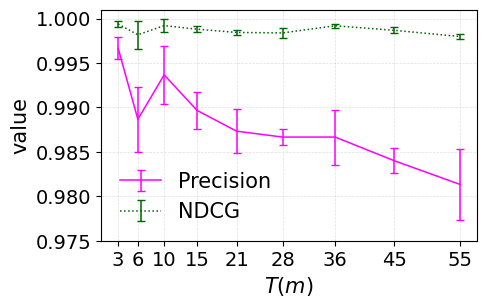

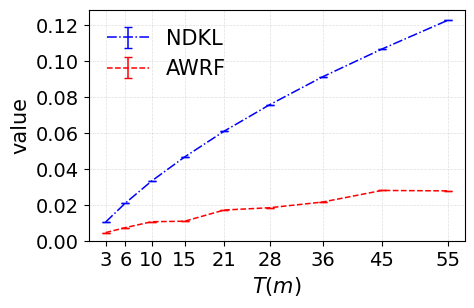

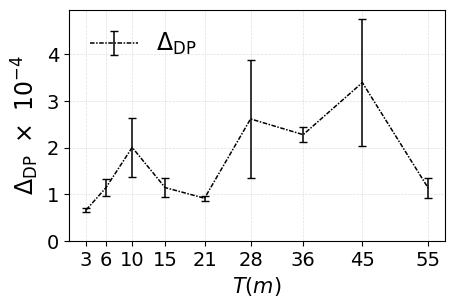

In [6]:
fs = 14

plot_two_metrics(
    df_precision, "Precision", "magenta", "solid",
    df_ndcg, "NDCG", "darkgreen", "dotted",
    fs = fs,
    ylabel = "value",
    savepath = "../figures/credit_utility_vs_Tm.pdf",
    ylim = (0.975, 1.001)
)

plot_two_metrics(
    df_ndkl, "NDKL", "blue", "-.",
    df_awrf, "AWRF", "red", "--",
    fs = fs,
    ylabel = "value",
    savepath = "../figures/credit_fairness_vs_Tm.pdf",
    ylim = (0, None)
)

plot_one_metric(
    df_dp,
    r"$\Delta_{\mathrm{DP}}$",
    ylabel=r"$\Delta_{\mathrm{DP}}$",
    fs = fs,
    linestyle = (0, (3, 1, 1, 1)),
    savepath = "../figures/credit_dp_vs_Tm.pdf",
    sci_y = True,
    sci_power = -4
)